# Clasificación ABC y política de reposición: análisis en Python

**Pregunta de negocio:** ¿qué productos concentran el 80% de las ventas y cuánto stock de seguridad y punto de reorden (ROP) necesita cada uno para evitar quiebres sin sobrestockear?

Supermercado **ficticio** de Lima: 500 SKU, 5 categorías, 24 meses (oct-2024 a sep-2026), un centro de distribución, importes en soles (S/).
Los datos son **sintéticos** y se generaron con un script propio en Python.

Contenido:
1. Carga de datos
2. Validación de calidad
3. Clasificación ABC
4. Diagnóstico de la política actual
5. Demanda diaria (con la trampa de los días sin venta)
6. Lead time real por SKU
7. Stock de seguridad y ROP recomendado
8. ¿De dónde sale la brecha?
9. Impacto por clase ABC y categoría
10. Exportar resultados
11. Conclusiones y limitaciones

## 1. Carga de datos
Se leen las 5 tablas desde una base SQLite local (`data/raw/inventario.db`), que no se incluye en el repositorio por su tamaño.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# El notebook puede ejecutarse desde la raíz del repo o desde notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = RAIZ / "data" / "raw" / "inventario.db"
IMAGENES = RAIZ / "docs" / "images"
IMAGENES.mkdir(parents=True, exist_ok=True)

with sqlite3.connect(DB) as con:
    productos = pd.read_sql("SELECT * FROM productos", con)
    ventas = pd.read_sql("SELECT * FROM ventas", con, parse_dates=["fecha"])
    inventario = pd.read_sql("SELECT * FROM inventario", con)
    pedidos = pd.read_sql("SELECT * FROM pedidos_proveedor", con,
                          parse_dates=["fecha_pedido", "fecha_entrega_prometida", "fecha_recepcion"])
    stock_diario = pd.read_sql("SELECT * FROM stock_diario", con, parse_dates=["fecha"])

tablas = {"productos": productos, "ventas": ventas, "inventario": inventario,
          "pedidos_proveedor": pedidos, "stock_diario": stock_diario}
pd.DataFrame({nombre: {"filas": len(df), "columnas": df.shape[1]} for nombre, df in tablas.items()}).T

,filas,columnas
productos,500,7
ventas,148303,4
inventario,500,3
pedidos_proveedor,19924,8
stock_diario,365000,3


In [2]:
# Estilo común de los gráficos: fondo claro, ejes discretos, sin bordes superior/derecho
AZUL, NARANJA, GRIS, TEXTO = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": TEXTO, "xtick.color": TEXTO, "ytick.color": TEXTO,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})

## 2. Validación de calidad
Antes de calcular nada se revisa que los datos tengan sentido: nulos, duplicados, valores imposibles y llaves que cruzan entre tablas.
Aunque los datos sean sintéticos, este paso es obligatorio: en una empresa real es donde aparecen la mayoría de los problemas.

In [3]:
chequeos = {
    "nulos en total (5 tablas)": sum(int(df.isna().sum().sum()) for df in tablas.values()),
    "filas duplicadas (5 tablas)": sum(int(df.duplicated().sum()) for df in tablas.values()),
    "ventas duplicadas por fecha + sku": int(ventas.duplicated(["fecha", "sku"]).sum()),
    "ventas con unidades <= 0": int((ventas["unidades"] <= 0).sum()),
    "stock de cierre negativo": int((stock_diario["stock_cierre"] < 0).sum()),
    "productos con precio <= costo": int((productos["precio_venta"] <= productos["costo_unitario"]).sum()),
    "pedidos recibidos > pedidos": int((pedidos["cantidad_recibida"] > pedidos["cantidad_pedida"]).sum()),
    "sku de ventas que no están en productos": int((~ventas["sku"].isin(productos["sku"])).sum()),
    "sku de pedidos que no están en productos": int((~pedidos["sku"].isin(productos["sku"])).sum()),
    "días-SKU esperados en stock_diario (500 x 730)": 500 * 730 - len(stock_diario),
}
pd.Series(chequeos, name="problemas encontrados").to_frame()

,problemas encontrados
nulos en total (5 tablas),0
filas duplicadas (5 tablas),0
ventas duplicadas por fecha + sku,0
ventas con unidades <= 0,0
stock de cierre negativo,0
productos con precio <= costo,0
pedidos recibidos > pedidos,0
sku de ventas que no están en productos,0
sku de pedidos que no están en productos,0
días-SKU esperados en stock_diario (500 x 730),0


Todos los chequeos dan 0: no hace falta limpiar filas. Lo que sí hace falta es **completar** la tabla de ventas, porque solo trae los días con venta (sección 5).

## 3. Clasificación ABC
Se ordenan los SKU por importe vendido (24 meses) y se acumula el porcentaje. **A** = hasta el 80% acumulado, **B** = hasta el 95%, **C** = el resto.
Es la misma lógica de `sql/02_clasificacion_abc.sql`, así que sirve también para validar la consulta.

In [4]:
importe = (ventas.assign(importe=ventas["unidades"] * ventas["precio_venta"])
                 .groupby("sku")["importe"].sum()
                 .sort_values(ascending=False))
abc = importe.to_frame()
abc["pct_acumulado"] = abc["importe"].cumsum() / abc["importe"].sum()
abc["clase_abc"] = np.select([abc["pct_acumulado"] <= 0.80, abc["pct_acumulado"] <= 0.95], ["A", "B"], "C")

resumen_abc = abc.groupby("clase_abc").agg(n_sku=("importe", "size"), importe=("importe", "sum"))
resumen_abc["pct_sku"] = (100 * resumen_abc["n_sku"] / resumen_abc["n_sku"].sum()).round(1)
resumen_abc["pct_importe"] = (100 * resumen_abc["importe"] / resumen_abc["importe"].sum()).round(1)
resumen_abc

,n_sku,importe,pct_sku,pct_importe
clase_abc,,,,
A,95,3970387.62,19.0,80.0
B,213,744286.33,42.6,15.0
C,192,249891.21,38.4,5.0


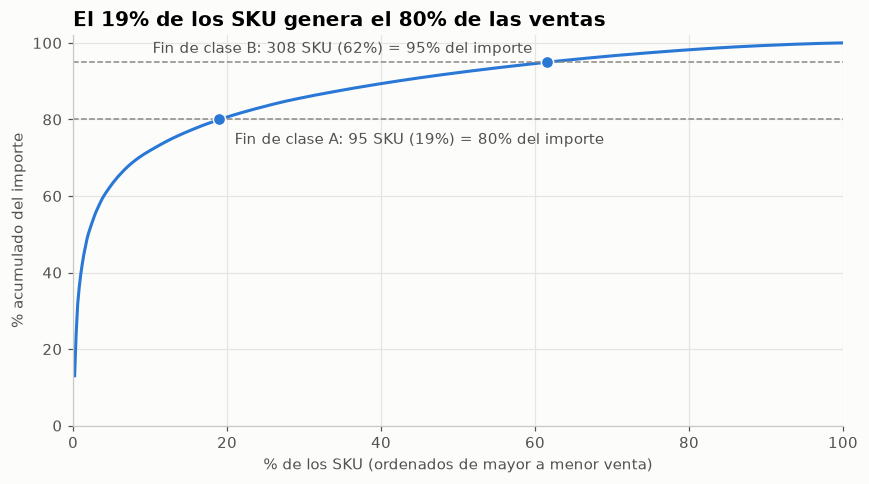

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = 100 * np.arange(1, len(abc) + 1) / len(abc)
ax.plot(x, 100 * abc["pct_acumulado"], color=AZUL, linewidth=2)
for corte, clase, offset, alineacion in [(80, "A", (10, -16), "left"), (95, "B", (-10, 6), "right")]:
    n = int((100 * abc["pct_acumulado"] <= corte).sum())
    ax.axhline(corte, color=GRIS, linewidth=1, linestyle="--")
    ax.plot(100 * n / len(abc), corte, "o", color=AZUL, markersize=8, markeredgecolor="#fcfcfb")
    ax.annotate(f"Fin de clase {clase}: {n} SKU ({100 * n / len(abc):.0f}%) = {corte}% del importe",
                xy=(100 * n / len(abc), corte), xytext=offset, textcoords="offset points", ha=alineacion, color=TEXTO)
ax.set(xlim=(0, 100), ylim=(0, 102), xlabel="% de los SKU (ordenados de mayor a menor venta)",
       ylabel="% acumulado del importe")
ax.set_title("El 19% de los SKU genera el 80% de las ventas")
fig.tight_layout()
fig.savefig(IMAGENES / "01_pareto_abc.png", dpi=150)
plt.show()

## 4. Diagnóstico de la política actual
El supermercado pide cuando el stock baja de `stock_minimo_actual`, que funciona como su punto de reorden.
La forma correcta de evaluar un ROP es el **nivel de servicio por ciclo**: de cada 100 pedidos, ¿en cuántos el stock **no** llegó a cero mientras se esperaba la entrega?

Ojo: es distinto del 96.5% de días con stock (de la consulta 04). Ese indicador mide disponibilidad diaria; este mide si el ROP alcanza para cubrir el lead time, que es justamente lo que se quiere dimensionar.

In [6]:
# Un ciclo "falla" si hubo algún día con stock 0 entre el pedido y la recepción
dias_cero = stock_diario.loc[stock_diario["stock_cierre"] == 0, ["sku", "fecha"]]
cruce = pedidos[["id_pedido", "sku", "fecha_pedido", "fecha_recepcion"]].merge(dias_cero, on="sku")
en_espera = (cruce["fecha"] > cruce["fecha_pedido"]) & (cruce["fecha"] < cruce["fecha_recepcion"])
pedidos["quiebre_en_ciclo"] = pedidos["id_pedido"].isin(cruce.loc[en_espera, "id_pedido"])

servicio_ciclo = (pedidos.merge(productos[["sku", "categoria"]], on="sku")
                         .groupby("categoria")["quiebre_en_ciclo"]
                         .agg(lambda s: 100 * (1 - s.mean()))
                         .sort_values())
servicio_global = 100 * (1 - pedidos["quiebre_en_ciclo"].mean())
print(f"Nivel de servicio por ciclo, global: {servicio_global:.1f}%  (objetivo: 95%)")
servicio_ciclo.round(1).rename("nivel_servicio_ciclo_%").to_frame()

Nivel de servicio por ciclo, global: 74.4%  (objetivo: 95%)


,nivel_servicio_ciclo_%
categoria,
Limpieza,69.8
Cuidado Personal,72.8
Bebidas,74.9
Abarrotes,75.5
Lácteos y Refrigerados,78.5


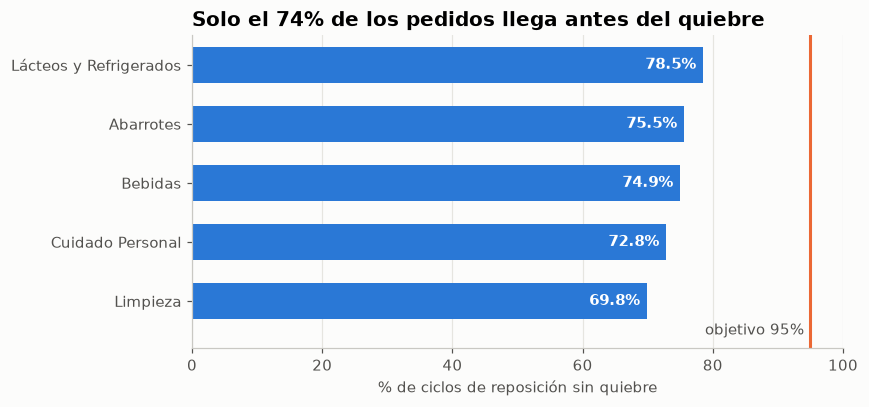

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(servicio_ciclo.index, servicio_ciclo.values, color=AZUL, height=0.6)
ax.axvline(95, color=NARANJA, linewidth=2)
ax.text(94, -0.5, "objetivo 95%", color=TEXTO, va="center", ha="right")
for i, v in enumerate(servicio_ciclo.values):
    ax.text(v - 1, i, f"{v:.1f}%", va="center", ha="right", color="white", fontweight="bold")
ax.set(xlim=(0, 100), xlabel="% de ciclos de reposición sin quiebre")
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.8, len(servicio_ciclo) - 0.5)
ax.set_title(f"Solo el {servicio_global:.0f}% de los pedidos llega antes del quiebre")
fig.tight_layout()
fig.savefig(IMAGENES / "02_servicio_por_ciclo.png", dpi=150)
plt.show()

In [8]:
# El lead time real promedio supera al planificado: hay retrasos que la política no considera
pedidos["tarde"] = pedidos["fecha_recepcion"] > pedidos["fecha_entrega_prometida"]
lt = (pedidos.merge(productos[["sku", "categoria", "lead_time_dias"]], on="sku")
             .groupby("categoria")
             .agg(lt_planificado=("lead_time_dias", "mean"),
                  lt_real=("lead_time_real_dias", "mean"),
                  pct_pedidos_tarde=("tarde", "mean")))
lt["pct_pedidos_tarde"] *= 100
lt.round(1)

,lt_planificado,lt_real,pct_pedidos_tarde
categoria,,,
Abarrotes,6.9,7.4,28.3
Bebidas,5.1,5.6,28.8
Cuidado Personal,8.3,8.7,26.6
Limpieza,8.9,9.5,28.6
Lácteos y Refrigerados,3.0,3.5,27.9


## 5. Demanda diaria: la trampa de los días sin venta
La tabla `ventas` **solo trae los días en que hubo venta**. Si se calcula el promedio y la desviación directamente sobre ella, se ignoran los días con 0 unidades y la demanda sale inflada.

Solución en dos pasos:
1. Partir de `stock_diario`, que tiene **todos** los días para todos los SKU, y pegarle las ventas: los días sin venta quedan en 0.
2. **Excluir los días en quiebre** (stock 0 al cierre). Ese día la venta fue menor que la demanda (no había producto), así que no refleja la demanda real.

Se usan los **últimos 12 meses** (oct-2025 a sep-2026): es lo bastante reciente para reflejar la tendencia y lo bastante largo para incluir todos los picos de temporada.

In [9]:
INICIO = pd.Timestamp("2025-10-01")

diario = (stock_diario[stock_diario["fecha"] >= INICIO]
          .merge(ventas[["fecha", "sku", "unidades"]], on=["fecha", "sku"], how="left")
          .fillna({"unidades": 0}))
diario_sin_quiebre = diario[diario["stock_cierre"] > 0]

demanda = diario_sin_quiebre.groupby("sku")["unidades"].agg(d_media="mean", d_sd="std", dias_usados="size")

# ¿Cuánto se equivocaría el cálculo ingenuo (solo días con venta)?
ingenua = ventas[ventas["fecha"] >= INICIO].groupby("sku")["unidades"].mean()
sesgo = (ingenua / demanda["d_media"]).median()
print(f"Días-SKU excluidos por quiebre: {100 * (1 - len(diario_sin_quiebre) / len(diario)):.1f}%")
print(f"Usar solo los días con venta inflaría la demanda media {sesgo:.1f} veces (mediana de los SKU)")
demanda.describe().round(2)

Días-SKU excluidos por quiebre: 3.9%
Usar solo los días con venta inflaría la demanda media 3.2 veces (mediana de los SKU)


,d_media,d_sd,dias_usados
count,500.00,500.00,500.00
mean,2.04,1.35,350.72
std,11.55,5.14,11.51
min,0.13,0.35,254.00
25%,0.24,0.49,346.00
50%,0.38,0.62,353.00
75%,0.85,0.97,358.25
max,217.27,102.62,365.00


## 6. Lead time real por SKU
De `pedidos_proveedor` se toma, para cada SKU, el **promedio** y la **desviación estándar** del lead time real (24 meses, entre 17 y 78 pedidos por SKU).
Se usa el lead time **real** y no el planificado porque el stock de seguridad tiene que cubrir lo que de verdad tarda el proveedor.

In [10]:
lead_time = pedidos.groupby("sku")["lead_time_real_dias"].agg(lt_media="mean", lt_sd="std", n_pedidos="size")
lead_time.describe().round(2)

,lt_media,lt_sd,n_pedidos
count,500.00,500.00,500.00
mean,7.03,1.11,39.85
std,2.78,0.26,13.23
min,2.15,0.39,17.00
25%,4.56,0.94,29.00
50%,6.62,1.11,39.00
75%,9.44,1.29,48.00
max,12.74,1.79,78.00


## 7. Stock de seguridad y ROP recomendado
Fórmula para demanda y lead time variables:

$$SS = z \cdot \sqrt{LT \cdot \sigma_d^2 + d^2 \cdot \sigma_{LT}^2} \qquad ROP = d \cdot LT + SS$$

- $d$, $\sigma_d$: demanda diaria media y su desviación (sección 5)
- $LT$, $\sigma_{LT}$: lead time real medio y su desviación, en días (sección 6)
- $z = 1.65$ → 95% de nivel de servicio por ciclo

El ROP se redondea hacia arriba (no se piden fracciones de unidad).
**Brecha = ROP recomendado − stock mínimo actual**: positiva significa que hoy se pide demasiado tarde.

In [11]:
Z = 1.65

repo = (productos
        .merge(inventario, on="sku")
        .merge(demanda, on="sku")
        .merge(lead_time, on="sku")
        .merge(abc["clase_abc"], left_on="sku", right_index=True))

repo["stock_seguridad"] = np.ceil(Z * np.sqrt(repo["lt_media"] * repo["d_sd"] ** 2
                                              + repo["d_media"] ** 2 * repo["lt_sd"] ** 2))
repo["rop_recomendado"] = np.ceil(repo["d_media"] * repo["lt_media"] + repo["stock_seguridad"])
repo["brecha_unidades"] = repo["rop_recomendado"] - repo["stock_minimo_actual"]
repo["brecha_pct"] = 100 * repo["brecha_unidades"] / repo["stock_minimo_actual"]
# Inversión adicional que exige subir el ROP: las unidades extra valorizadas a costo
repo["inversion_adicional"] = repo["brecha_unidades"].clip(lower=0) * repo["costo_unitario"]

print(f"SKU con ROP actual insuficiente: {(repo['brecha_unidades'] > 0).sum()} de {len(repo)}")
print(f"SKU con ROP actual excesivo:     {(repo['brecha_unidades'] < 0).sum()}")
print(f"Brecha mediana: +{repo['brecha_pct'].median():.0f}%")
print(f"Inversión adicional total: S/ {repo['inversion_adicional'].sum():,.0f}")

cols = ["sku", "nombre", "clase_abc", "d_media", "lt_media", "stock_seguridad",
        "stock_minimo_actual", "rop_recomendado", "brecha_unidades", "inversion_adicional"]
repo.sort_values("inversion_adicional", ascending=False)[cols].head(10).round(2)

SKU con ROP actual insuficiente: 498 de 500
SKU con ROP actual excesivo:     0
Brecha mediana: +50%
Inversión adicional total: S/ 20,539


,sku,nombre,clase_abc,d_media,lt_media,stock_seguridad,stock_minimo_actual,rop_recomendado,brecha_unidades,inversion_adicional
484,SKU0485,Gaseosa cola 3 L - Brisa Andina,A,217.27,3.56,476.0,755,1250.0,495.0,1851.30
205,SKU0206,Galletas de soda 6 und - Pampa Real,A,100.65,6.54,203.0,604,862.0,258.0,1787.94
92,SKU0093,Café molido 200 g - Brisa Andina,A,62.29,10.31,167.0,633,809.0,176.0,1341.12
375,SKU0376,Desodorante 150 ml - Brisa Andina,A,16.40,11.42,52.0,179,240.0,61.0,822.28
181,SKU0182,Azúcar rubia 1 kg - Brisa Andina,A,34.74,6.31,77.0,211,297.0,86.0,620.06
403,SKU0404,Mermelada de fresa 250 g - Campo Fresco,A,20.33,7.43,67.0,156,219.0,63.0,411.39
335,SKU0336,Gaseosa cola 3 L - Nevado,A,13.65,7.44,34.0,103,136.0,33.0,398.97
170,SKU0171,Desodorante 50 ml - Brisa Andina,A,4.74,6.64,15.0,32,47.0,15.0,338.10
165,SKU0166,Esponja de cocina 2 und - Valle Dorado,A,11.99,11.61,36.0,129,176.0,47.0,297.51
357,SKU0358,Gaseosa lima-limón 1.5 L - Sol Naciente,A,45.25,4.36,116.0,209,314.0,105.0,287.70


## 8. ¿De dónde sale la brecha?
Para saber **qué** está mal en la política actual, se recalcula el ROP total (suma de los 500 SKU) agregando un factor a la vez:

1. **Demanda real**: usar la demanda y la variabilidad medidas en el último año (con el z = 1 y el lead time planificado de hoy).
2. **Nivel de servicio**: subir z de 1.0 (≈84%) a 1.65 (95%).
3. **Retrasos**: usar el lead time real medio en vez del planificado.
4. **Variabilidad del lead time**: sumar el término $d^2 \cdot \sigma_{LT}^2$.

In [12]:
def rop_total(d, sd, lt, z, sd_lt=0):
    # Mismo redondeo que en la sección 7: primero el stock de seguridad, luego el ROP
    ss = np.ceil(z * np.sqrt(lt * sd ** 2 + d ** 2 * sd_lt ** 2))
    return np.ceil(d * lt + ss).sum()

r = repo
pasos = {
    "ROP actual": r["stock_minimo_actual"].sum(),
    "Demanda real": rop_total(r["d_media"], r["d_sd"], r["lead_time_dias"], 1.0),
    "z = 1.65": rop_total(r["d_media"], r["d_sd"], r["lead_time_dias"], Z),
    "Lead time real": rop_total(r["d_media"], r["d_sd"], r["lt_media"], Z),
    "Variabilidad LT": rop_total(r["d_media"], r["d_sd"], r["lt_media"], Z, r["lt_sd"]),
}
puente = pd.Series(pasos, name="rop_total_unidades").astype(int).to_frame()
puente["aumento"] = puente["rop_total_unidades"].diff()
assert puente["rop_total_unidades"].iloc[-1] == repo["rop_recomendado"].sum()
puente

,rop_total_unidades,aumento
ROP actual,7165,NaN
Demanda real,8148,983.0
z = 1.65,9196,1048.0
Lead time real,9797,601.0
Variabilidad LT,10399,602.0


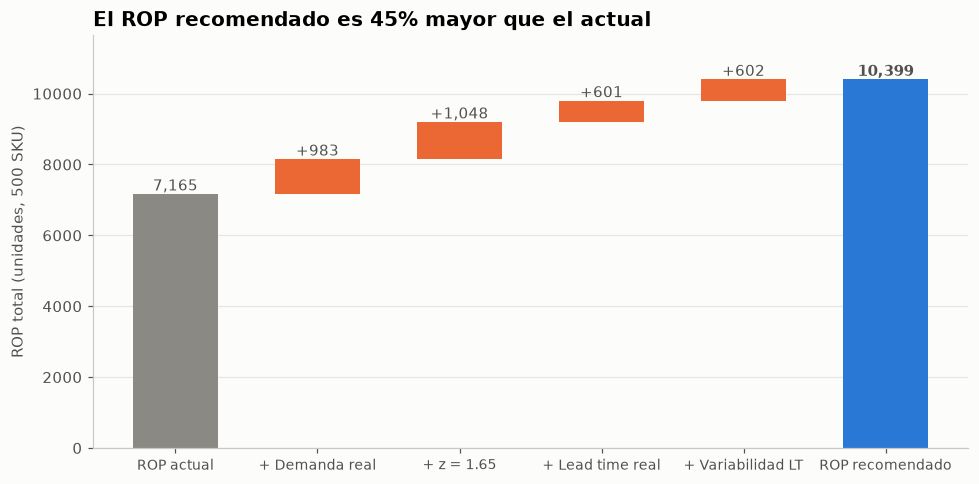

In [13]:
valores = puente["rop_total_unidades"].to_numpy()
etiquetas = list(puente.index[:1]) + [f"+ {e}" for e in puente.index[1:]] + ["ROP recomendado"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(0, valores[0], color=GRIS, width=0.6)
ax.text(0, valores[0], f"{valores[0]:,}", ha="center", va="bottom", color=TEXTO)
for i in range(1, len(valores)):
    delta = valores[i] - valores[i - 1]
    ax.bar(i, delta, bottom=valores[i - 1], color=NARANJA, width=0.6)
    ax.text(i, valores[i], f"+{delta:,}", ha="center", va="bottom", color=TEXTO)
ax.bar(len(valores), valores[-1], color=AZUL, width=0.6)
ax.text(len(valores), valores[-1], f"{valores[-1]:,}", ha="center", va="bottom", color=TEXTO, fontweight="bold")
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=0, fontsize=9)
ax.set(ylim=(0, valores[-1] * 1.12), ylabel="ROP total (unidades, 500 SKU)")
ax.grid(axis="x", visible=False)
ax.set_title(f"El ROP recomendado es {100 * (valores[-1] / valores[0] - 1):.0f}% mayor que el actual")
fig.tight_layout()
fig.savefig(IMAGENES / "03_puente_rop.png", dpi=150)
plt.show()

## 9. Impacto por clase ABC y categoría
¿Dónde hay que invertir primero? Se resume la inversión adicional y los quiebres por clase y por categoría.

In [14]:
pct_quiebre = (stock_diario.assign(quiebre=stock_diario["stock_cierre"] == 0)
                           .groupby("sku")["quiebre"].mean().rename("pct_dias_quiebre") * 100)
repo = repo.merge(pct_quiebre, on="sku")

def resumen(por):
    t = repo.groupby(por).agg(
        n_sku=("sku", "size"),
        rop_actual=("stock_minimo_actual", "sum"),
        rop_recomendado=("rop_recomendado", "sum"),
        inversion_adicional=("inversion_adicional", "sum"),
        pct_dias_quiebre=("pct_dias_quiebre", "mean"),
    )
    t["aumento_rop_pct"] = 100 * (t["rop_recomendado"] / t["rop_actual"] - 1)
    t["pct_de_la_inversion"] = 100 * t["inversion_adicional"] / t["inversion_adicional"].sum()
    return t.round(1)

resumen("clase_abc")

,n_sku,rop_actual,rop_recomendado,inversion_adicional,pct_dias_quiebre,aumento_rop_pct,pct_de_la_inversion
clase_abc,,,,,,,
A,95,5261,7567.0,14080.2,4.8,43.8,68.6
B,213,1241,1829.0,4628.7,3.8,47.4,22.5
C,192,663,1003.0,1829.9,2.6,51.3,8.9


In [15]:
resumen("categoria").sort_values("inversion_adicional", ascending=False)

,n_sku,rop_actual,rop_recomendado,inversion_adicional,pct_dias_quiebre,aumento_rop_pct,pct_de_la_inversion
categoria,,,,,,,
Abarrotes,140,2533,3546.0,6972.4,3.4,40.0,33.9
Cuidado Personal,90,1326,1840.0,4498.7,3.7,38.8,21.9
Bebidas,100,1861,2901.0,4390.5,3.2,55.9,21.4
Limpieza,90,1038,1442.0,3032.4,5.0,38.9,14.8
Lácteos y Refrigerados,80,407,670.0,1644.8,2.3,64.6,8.0


In [16]:
capital_actual = (repo["stock_actual"] * repo["costo_unitario"]).sum()
print(f"Capital inmovilizado hoy: S/ {capital_actual:,.0f}")
print(f"Inversión adicional recomendada: S/ {repo['inversion_adicional'].sum():,.0f} "
      f"(+{100 * repo['inversion_adicional'].sum() / capital_actual:.0f}% sobre el capital actual)")
# ¿La brecha de cada SKU explica sus quiebres? Correlación de Spearman = correlación de los rangos
print("Correlación brecha % vs % días en quiebre por SKU:",
      round(repo["brecha_pct"].rank().corr(repo["pct_dias_quiebre"].rank()), 2))

Capital inmovilizado hoy: S/ 53,412
Inversión adicional recomendada: S/ 20,539 (+38% sobre el capital actual)
Correlación brecha % vs % días en quiebre por SKU: -0.11


## 10. Exportar resultados
La tabla por SKU se guarda en `data/processed/reposicion_por_sku.csv` para usarla en el modelo de Excel y en el dashboard.

In [17]:
salida = RAIZ / "data" / "processed" / "reposicion_por_sku.csv"
salida.parent.mkdir(parents=True, exist_ok=True)
columnas = ["sku", "nombre", "categoria", "proveedor", "clase_abc", "costo_unitario",
            "d_media", "d_sd", "lead_time_dias", "lt_media", "lt_sd",
            "stock_actual", "stock_minimo_actual", "stock_seguridad", "rop_recomendado",
            "brecha_unidades", "brecha_pct", "inversion_adicional", "pct_dias_quiebre"]
repo[columnas].round(3).to_csv(salida, index=False)
print(f"Guardado: {salida.relative_to(RAIZ)} ({len(repo)} filas)")

Guardado: data\processed\reposicion_por_sku.csv (500 filas)


## 11. Conclusiones y limitaciones

**Hallazgos**
1. **Concentración:** 95 SKU (19%) generan el 80% del importe. Son los que más importa no quebrar.
2. **La política actual no cumple:** solo el **74.4%** de los ciclos de reposición termina sin quiebre, frente al 95% objetivo. La peor categoría es Limpieza (69.8%).
3. **El ROP está subdimensionado en casi todo el surtido:** en 498 de 500 SKU el ROP actual es menor que el recomendado, y en ninguno es mayor. El ROP total debería pasar de 7,165 a 10,399 unidades (**+45%**; brecha mediana por SKU: +50%).
4. **Por qué falla** (puente de la sección 8): la brecha se reparte en tres partes parecidas.
   - Demanda y variabilidad reales mayores que las supuestas: +983 unidades.
   - Nivel de servicio bajo (z = 1.0): +1,048 unidades.
   - Retrasos del proveedor no considerados (lead time real y su variabilidad): +1,203 unidades.
5. **Costo de corregirlo:** **S/ 20.5 mil** de inversión adicional en stock (+38% sobre el capital inmovilizado actual). El 69% corresponde a la clase A: con unos S/ 14 mil se protegen los 95 SKU que hacen el 80% de las ventas, que además son los que más días pasan en quiebre (4.8% frente a 2.6% en la clase C).

**Recomendación:** actualizar primero el ROP de la clase A con la fórmula que incluye la variabilidad del lead time, y revisar con compras los retrasos: el 28% de los pedidos llega tarde.

**Limitaciones (decirlas evita conclusiones falsas)**
- La brecha de cada SKU **no predice** cuál quiebra más (correlación de −0.11). El problema es sistemático, no de unos pocos productos. Por eso la evidencia es el nivel de servicio por ciclo y no una comparación SKU por SKU.
- Se usa un ROP único para todo el año. Con picos en diciembre y en verano (bebidas), lo ideal es un ROP por temporada.
- No se evaluó la cantidad de pedido (Q). El sobrestock, si existe, vendría de Q y no del ROP. Siguiente paso: EOQ o revisión periódica.
- Excluir los días en quiebre subestima un poco la demanda de los SKU que quiebran seguido.
- No se simuló el resultado de la nueva política. Siguiente paso: volver a correr la simulación con el ROP recomendado y medir el nivel de servicio.
- Los datos son **sintéticos**.